In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pycbc.noise import noise_from_psd
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.types import TimeSeries
from scipy.signal import butter, sosfiltfilt

np.random.seed(42)

/home/gopal/miniconda3/envs/gwenv/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(True)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


In [2]:
duration = 104.0       # seconds
fs = 2048             # Hz
dt = 1.0 / fs

# Total number of samples
N = int(duration * fs)

# Frequency resolution
delta_f = 1.0 / duration

# Band-pass frequencies
f_low = 30.0
f_high = 1000.0

print("Duration:", duration, "s")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", N)
print("delta_t:", dt, "s")
print("delta_f:", delta_f, "Hz")

Duration: 104.0 s
Sampling frequency: 2048 Hz
Number of samples: 212992
delta_t: 0.00048828125 s
delta_f: 0.009615384615384616 Hz


In [3]:
flen = N // 2 + 1
psd = aLIGOZeroDetHighPower(flen, delta_f, low_freq_cutoff=30.0)
freqs = np.arange(len(psd)) * delta_f
print("PSD length:", len(psd))
print("Maximum frequency:", freqs[-1], "Hz")

PSD length: 106497
Maximum frequency: 1024.0 Hz


In [4]:
h1_noise = noise_from_psd(N, dt, psd, seed=100)
l1_noise = noise_from_psd(N, dt, psd, seed=200)

print("H1 samples:", len(h1_noise))
print("L1 samples:", len(l1_noise))
print("H1 duration:", len(h1_noise) * dt, "s")
print("L1 duration:", len(l1_noise) * dt, "s")

H1 samples: 212992
L1 samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


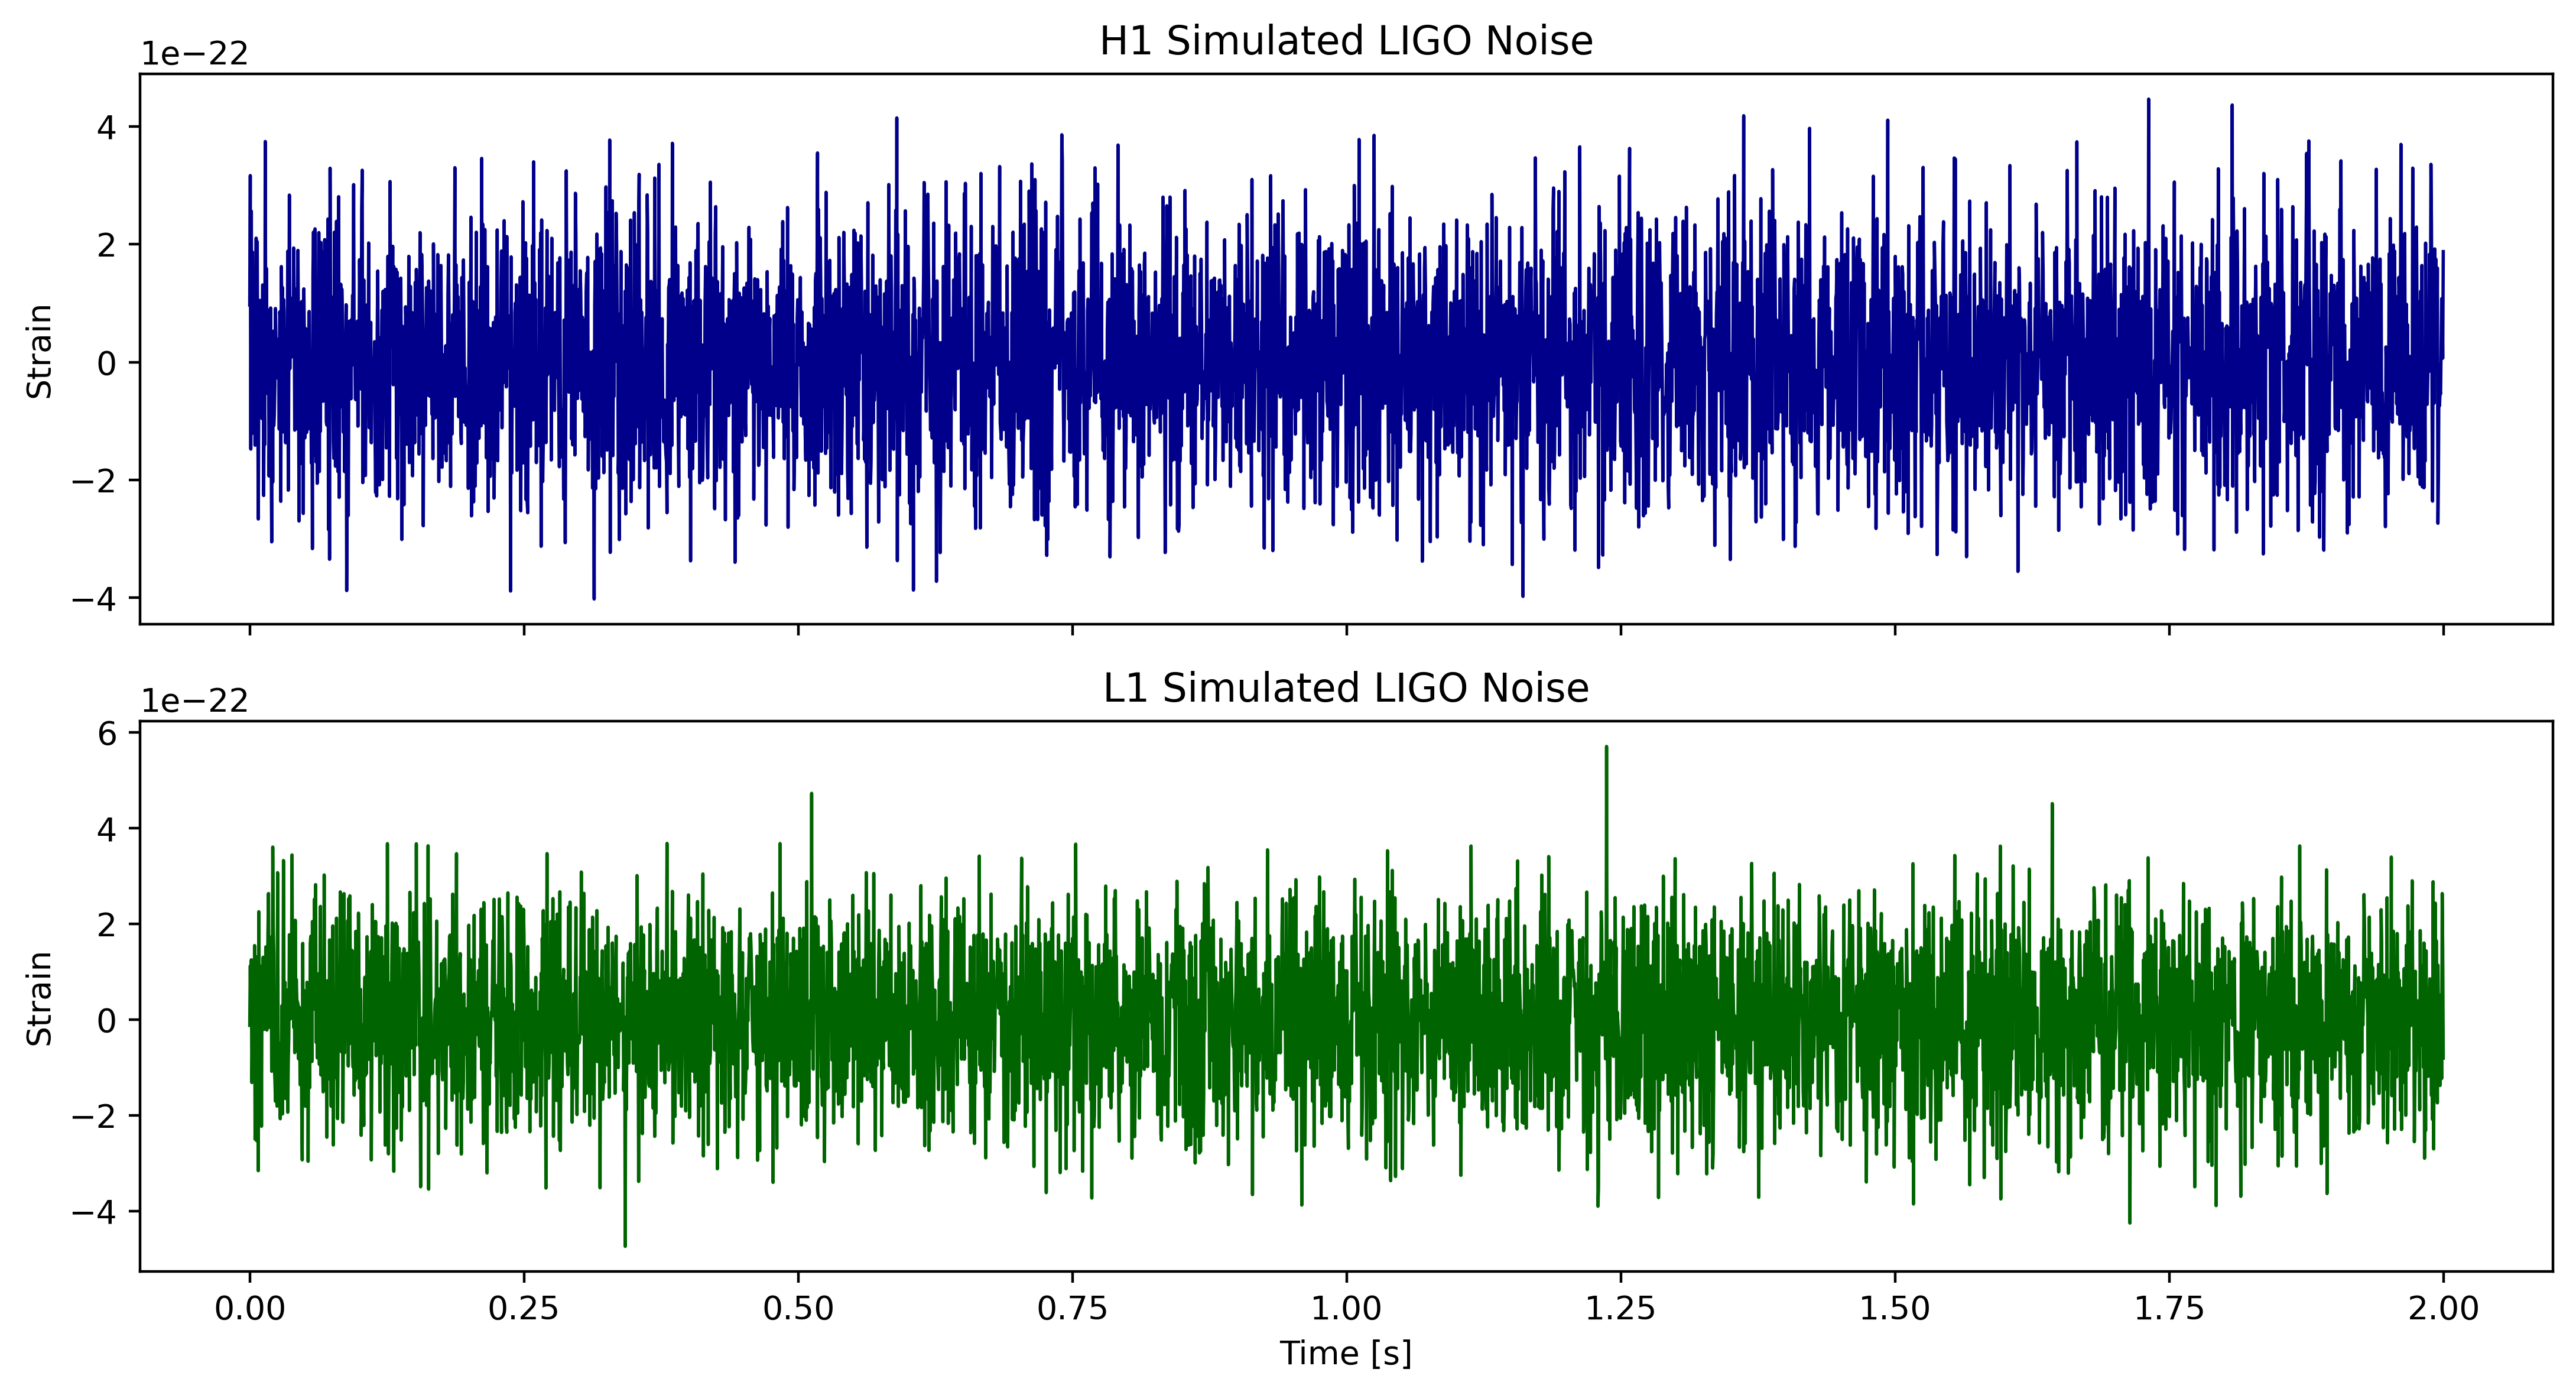

In [5]:
plot_duration = 2.0
nplot = int(plot_duration * fs)
time = np.arange(N) / fs
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, dpi = 400)

ax[0].plot(time[:nplot],h1_noise.numpy()[:nplot], color = "darkblue",linewidth= 1.0)
ax[0].set_ylabel("Strain")
ax[0].set_title("H1 Simulated LIGO Noise")
ax[1].plot(time[:nplot],l1_noise.numpy()[:nplot],color = "darkgreen",linewidth= 1.0)
ax[1].set_ylabel("Strain")
ax[1].set_xlabel("Time [s]")
ax[1].set_title("L1 Simulated LIGO Noise")

plt.tight_layout()
plt.show()

In [6]:
#QsSG = np.array([3, 9, 100])

# Function to calculate the characteristic duration tau
def SG_tau(Q, f0):
    tau = Q / (np.sqrt(2) * np.pi * f0)
    return tau


# Function to generate plus polarization
def SG_waveform(Q, f0, t, alpha, amplitude, shift):
    tau = SG_tau(Q, f0)

    # Central time of the waveform
    t0 = np.max(t) / 2
    t0 = t0 + shift

    # Shifted time coordinate
    tc = t - t0

    # Basic sine-Gaussian components
    H_plus = np.exp(-(tc**2 / tau**2)) * np.sin(2 * np.pi * f0 * tc)
    h_plus = amplitude * ((1 + alpha**2) / 2) * H_plus
   
    return h_plus

In [7]:
from pycbc.types import TimeSeries
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.filter import sigma

# 1 second time array
times = np.arange(0, 1.0, dt)

# Injection parameters
f0 = 900.0
Q = 100
#Q = QsSG[2]       # Q = 100
alpha = 0.8
target_snr = 15.0

# Generate unit-amplitude sine-Gaussian
SG_base = SG_waveform(Q,f0,times,alpha,amplitude=1.0,shift=0.0)

# Convert to PyCBC TimeSeries
SG_ts = TimeSeries(SG_base, delta_t=dt)

# Frequency resolution for a 1-second waveform
delta_f_sg = 1.0 / SG_ts.duration

# PSD sampled at the same frequency resolution as the SG
psd_sg = aLIGOZeroDetHighPower(len(SG_ts) // 2 + 1,delta_f_sg,low_freq_cutoff=30.0)

# SNR of the unit-amplitude waveform
snr_unit = sigma(SG_ts,psd=psd_sg,low_frequency_cutoff=30.0,high_frequency_cutoff=1000.0)

# Scale to target SNR = 15
scale_factor = target_snr / snr_unit
SG_scaled = SG_base * scale_factor

# Verify final SNR
SG_scaled_ts = TimeSeries(SG_scaled, delta_t=dt)
snr_final = sigma(SG_scaled_ts,psd=psd_sg,low_frequency_cutoff=30.0,high_frequency_cutoff=1000.0)

print("SG samples:", len(SG_scaled))
print("Unit SG SNR:", snr_unit)
print("Scale factor:", scale_factor)
print("Final SNR:", snr_final)

SG samples: 2048
Unit SG SNR: 2.955679967027289e+22
Scale factor: 5.074974343411893e-22
Final SNR: 15.000000000000004


In [8]:
# ============================================================
# Create injection streams:
#   - True SG signal in BOTH H1 and L1 at centre = 1024
#   - Additional glitch-like SG ONLY in H1 at centre = 1536
# ============================================================

# Empty 104-second injection streams
h1_injection = np.zeros(N)
l1_injection = np.zeros(N)

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

segment_samples = int(fs)      # 2048 samples = 1 second

signal_center = segment_samples // 2   # 1024
glitch_center = 1536

# Difference between normal SG centre and glitch centre
shift_samples = glitch_center - signal_center

print("Signal centre:", signal_center)
print("Glitch centre:", glitch_center)
print("Glitch shift:", shift_samples, "samples")
print("Glitch shift:", shift_samples / fs, "s")


# ------------------------------------------------------------
# Create shifted SG for the glitch
# Zero-padding is used instead of np.roll so that the waveform
# does not wrap around the edge of the 1-second segment.
# ------------------------------------------------------------

SG_glitch = np.zeros_like(SG_scaled)

if shift_samples > 0:
    SG_glitch[shift_samples:] = SG_scaled[:-shift_samples]

elif shift_samples < 0:
    SG_glitch[:shift_samples] = SG_scaled[-shift_samples:]

else:
    SG_glitch[:] = SG_scaled


# ------------------------------------------------------------
# Insert signals into each of the 100 future 1-second segments
# ------------------------------------------------------------

for i in range(100):

    start_idx = int((2 + i) * fs)
    end_idx = start_idx + segment_samples

    # ========================================================
    # TRUE COHERENT SIGNAL
    # Same SG in both detectors, centred at sample 1024
    # ========================================================

    h1_injection[start_idx:end_idx] += SG_scaled
    l1_injection[start_idx:end_idx] += SG_scaled


    # ========================================================
    # GLITCH
    # Additional SG only in H1, centred at sample 1546
    # ========================================================

    h1_injection[start_idx:end_idx] += SG_glitch


print("H1 injection length:", len(h1_injection))
print("L1 injection length:", len(l1_injection))

print("H1 injection duration:", len(h1_injection) / fs, "s")
print("L1 injection duration:", len(l1_injection) / fs, "s")

Signal centre: 1024
Glitch centre: 1536
Glitch shift: 512 samples
Glitch shift: 0.25 s
H1 injection length: 212992
L1 injection length: 212992
H1 injection duration: 104.0 s
L1 injection duration: 104.0 s


In [9]:
# Add the injections to the original colored LIGO-like noise

h1_signal_noise = h1_noise.numpy() + h1_injection
l1_signal_noise = l1_noise.numpy() + l1_injection

print("H1 signal+noise samples:", len(h1_signal_noise))
print("L1 signal+noise samples:", len(l1_signal_noise))
print("H1 duration:", len(h1_signal_noise) / fs, "s")
print("L1 duration:", len(l1_signal_noise) / fs, "s")

H1 signal+noise samples: 212992
L1 signal+noise samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


In [10]:
def whiten_with_psd(data, psd, fs):
    x = np.asarray(data, dtype=np.float64)
    N = len(x)
    dt = 1.0 / fs

    # FFT
    hf = np.fft.rfft(x)

    # PSD as numpy array
    psd_array = np.asarray(psd)

    # Avoid division by zero
    valid = psd_array > 0
    white_hf = np.zeros_like(hf, dtype=complex)

    # Whiten in frequency domain
    white_hf[valid] = hf[valid] / np.sqrt(psd_array[valid])

    # Back to time domain
    white = np.fft.irfft(white_hf, n=N)

    # Normalize scale
    white *= np.sqrt(2.0 * dt)

    return white

In [11]:
h1_whitened = whiten_with_psd(h1_signal_noise,psd,fs)
l1_whitened = whiten_with_psd(l1_signal_noise,psd,fs)

print("H1 whitened samples:", len(h1_whitened))
print("L1 whitened samples:", len(l1_whitened))
print("H1 duration:", len(h1_whitened) / fs, "s")
print("L1 duration:", len(l1_whitened) / fs, "s")

H1 whitened samples: 212992
L1 whitened samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


In [12]:
def bandpass_filter(data, fs, lowcut=30.0, highcut=300.0, order=4):
    sos = butter(order,[lowcut, highcut],btype="bandpass",fs=fs,output="sos")
    filtered = sosfiltfilt(sos, data)

    return filtered

In [13]:
h1_whitened_bp = bandpass_filter(h1_whitened,fs,lowcut=f_low,highcut=f_high)
l1_whitened_bp = bandpass_filter(l1_whitened,fs,lowcut=f_low,highcut=f_high)

print("H1 final shape:", h1_whitened_bp.shape)
print("L1 final shape:", l1_whitened_bp.shape)
print("H1 duration:", len(h1_whitened_bp) / fs, "s")
print("L1 duration:", len(l1_whitened_bp) / fs, "s")

H1 final shape: (212992,)
L1 final shape: (212992,)
H1 duration: 104.0 s
L1 duration: 104.0 s


In [14]:
# Remove 2 seconds from the beginning and end
trim_seconds = 2
trim_samples = int(trim_seconds * fs)
h1_trimmed = h1_whitened_bp[trim_samples:-trim_samples]
l1_trimmed = l1_whitened_bp[trim_samples:-trim_samples]

print("Samples removed from each edge:", trim_samples)
print("H1 trimmed samples:", len(h1_trimmed))
print("L1 trimmed samples:", len(l1_trimmed))
print("H1 trimmed duration:", len(h1_trimmed) / fs, "s")
print("L1 trimmed duration:", len(l1_trimmed) / fs, "s")

Samples removed from each edge: 4096
H1 trimmed samples: 204800
L1 trimmed samples: 204800
H1 trimmed duration: 100.0 s
L1 trimmed duration: 100.0 s


In [15]:
# Split 100 seconds streams into 100 one second segments
samples_per_file = fs   # 2048 samples = 1 second

H1_segments = h1_trimmed.reshape(100, samples_per_file)
L1_segments = l1_trimmed.reshape(100, samples_per_file)

print("H1 segments shape:", H1_segments.shape)
print("L1 segments shape:", L1_segments.shape)
print("Samples in each H1 file:", H1_segments.shape[1])
print("Samples in each L1 file:", L1_segments.shape[1])

H1 segments shape: (100, 2048)
L1 segments shape: (100, 2048)
Samples in each H1 file: 2048
Samples in each L1 file: 2048


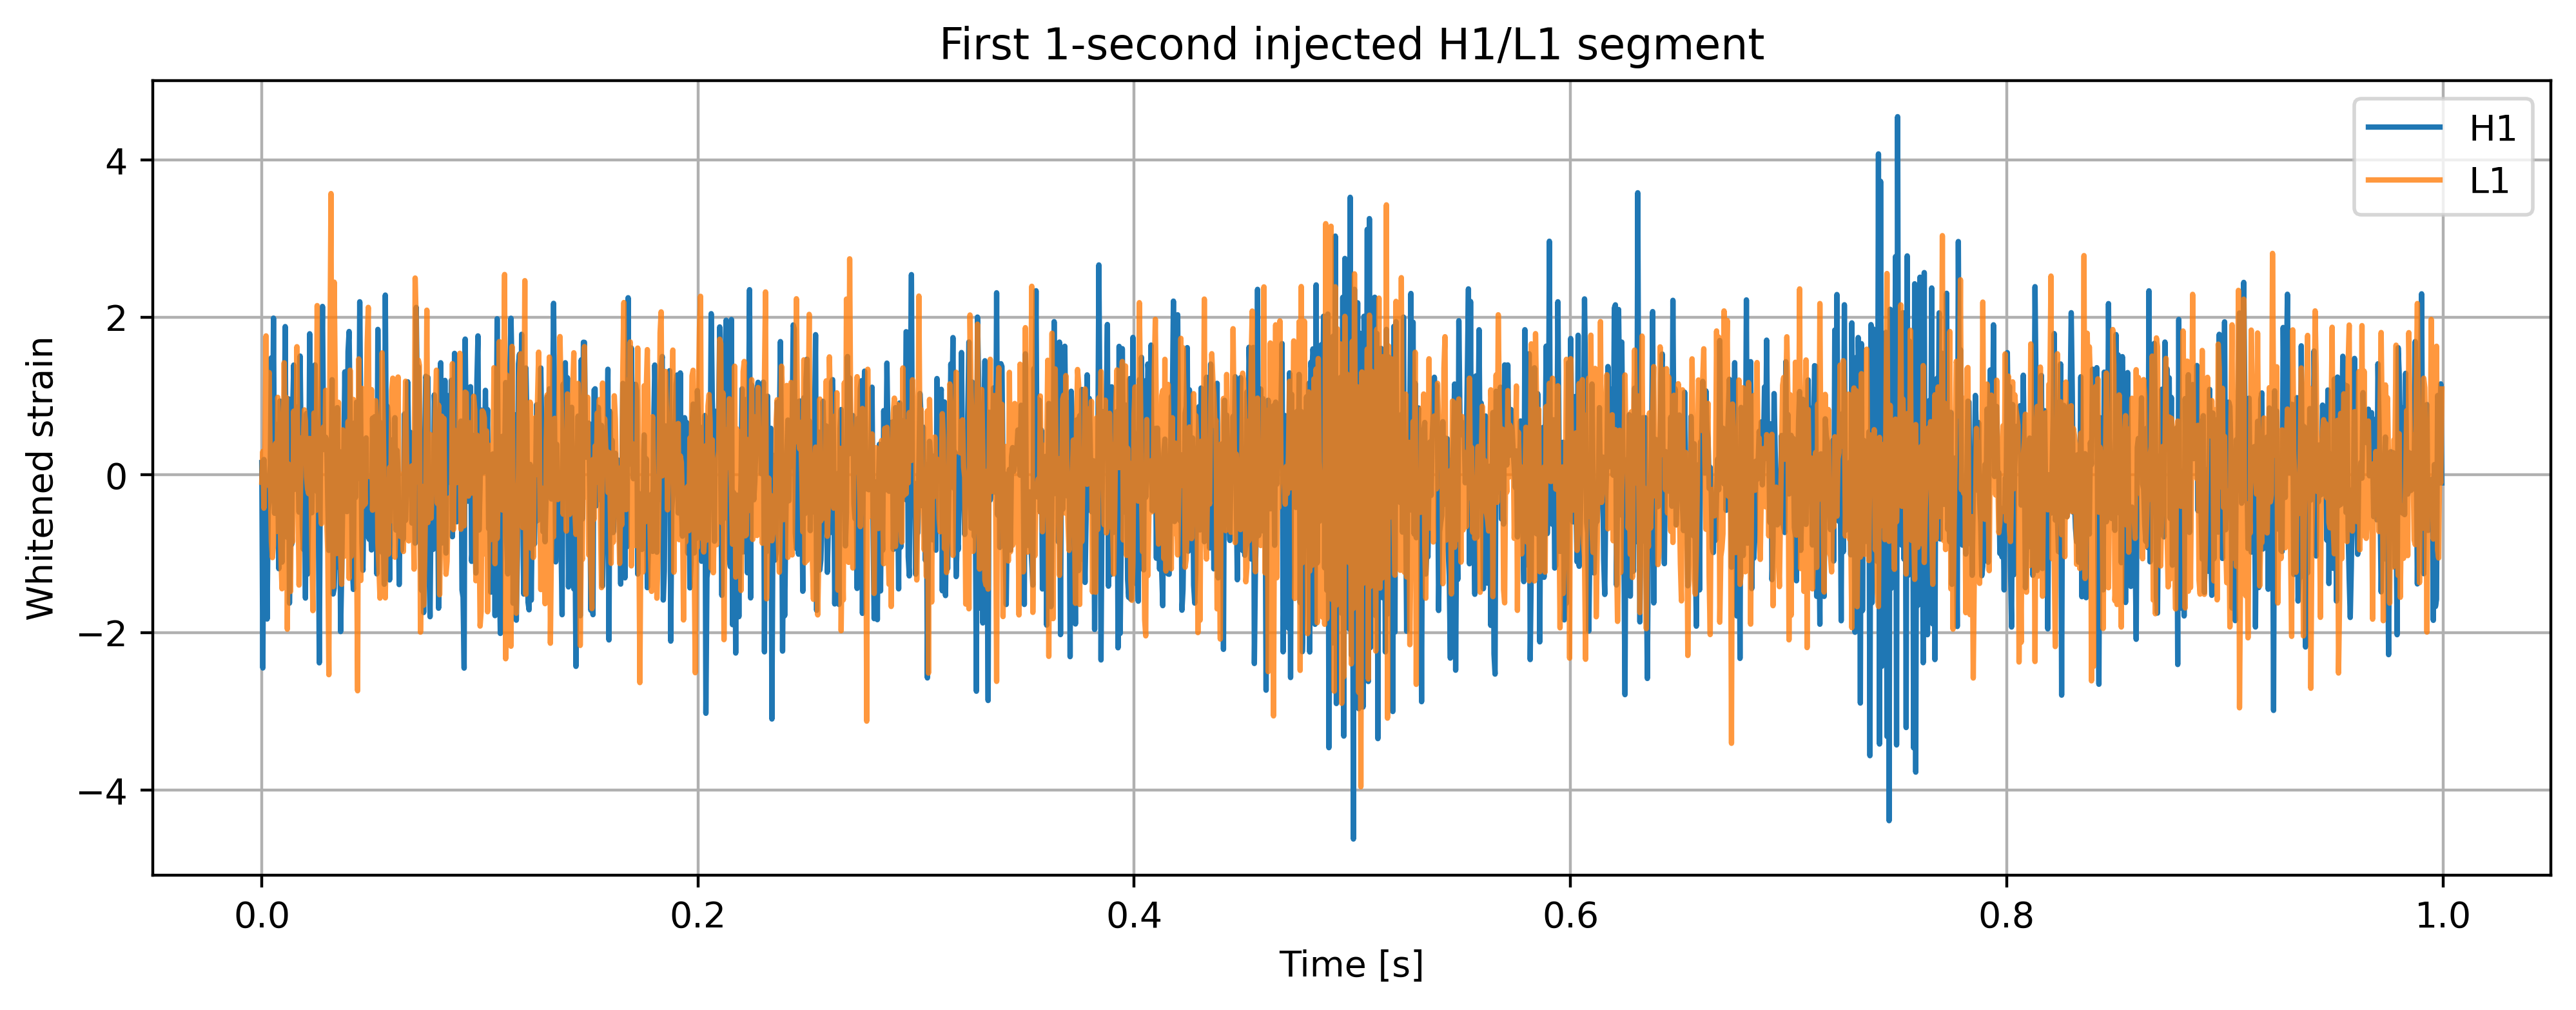

In [16]:
t1 = np.arange(2048) / fs

plt.figure(figsize=(12, 4), dpi = 400)
plt.plot(t1, H1_segments[0], label='H1')
plt.plot(t1, L1_segments[0], label='L1', alpha=0.8)
plt.xlabel('Time [s]')
plt.ylabel('Whitened strain')
plt.title('First 1-second injected H1/L1 segment')
plt.legend()
plt.grid()
plt.show()

In [17]:
# Simple dot product correlation between two arrays
def cc(x, y):
    correlation = sum(a * b for a, b in zip(x, y))
    return correlation

# Cross correlation between H1 and L1
def cross_correlation_real_detector(data1, data2, times):

    # Remove mean
    data1 = data1 - np.mean(data1)
    data2 = data2 - np.mean(data2)
    correlations = []

    # Lag range
    lags = np.arange(-len(times)//2, len(times)//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))
        correlation = cc(data1_shifted, data2)

        # Normalize by segment length
        correlation = correlation / len(times)
        correlations.append(correlation)

    correlations = np.array(correlations)
    return correlations, lags

In [18]:
# Build 100 test files using 4 BLOCKS
# Final arrangement:
#   Block 1: 0:800       -> Noise
#   Block 2: 800:1300    -> True coherent signal
#   Block 3: 1300:1750   -> H1-only glitch
#   Block 4: 1750:2048   -> Noise
# Labels:
#   0.0 = Noise
#   1.0 = True coherent signal
#   0.5 = One-stream glitch

import os
import numpy as np

# Save folders

save_folder = "../TranAD_MGB/data/GW_sim_900_snr15_ng/test/"
label_folder = "../TranAD_MGB/data/GW_sim_900_snr15_ng/labels/"

os.makedirs(save_folder, exist_ok=True)
os.makedirs(label_folder, exist_ok=True)

num_files = 100
fs = 2048
dt = 1.0 / fs
segment_samples = 2048

# Signal is centered at 1024
# Glitch is centered at 1536

block1_start = 0
block1_end   = 800

block2_start = 800
block2_end   = 1300

block3_start = 1300
block3_end   = 1750

block4_start = 1750
block4_end   = 2048

final_sigs = []
maxccs = []

# LOOP OVER 100 TEST SEGMENTS
for i in range(num_files):
    # Complete 1-second detector streams
    # H1: noise + coherent SG @ 1024 + glitch @ 1536
    # L1: noise + coherent SG @ 1024
    h1 = np.asarray(H1_segments[i]).flatten()
    l1 = np.asarray(L1_segments[i]).flatten()

    # Remove mean
    h1 = h1 - np.mean(h1)
    l1 = l1 - np.mean(l1)

    # BLOCK 1: NOISE
    # samples 0:800
    h1_block1 = h1[block1_start:block1_end]
    l1_block1 = l1[block1_start:block1_end]

    # BLOCK 2: TRUE COHERENT SIGNAL
    # samples 800:1300
    # Contains SG centered at 1024 in BOTH H1 and L1
    h1_block2 = h1[block2_start:block2_end]
    l1_block2 = l1[block2_start:block2_end]

    # BLOCK 3: ONE-STREAM GLITCH
    # samples 1300:1750
    # Contains additional SG centered at 1536 in H1 ONLY
    h1_block3 = h1[block3_start:block3_end]
    l1_block3 = l1[block3_start:block3_end]

    # BLOCK 4: NOISE
    # samples 1750:2048
    h1_block4 = h1[block4_start:block4_end]
    l1_block4 = l1[block4_start:block4_end]

    # TIME ARRAYS FOR EACH BLOCk
    t_block1 = np.arange(len(h1_block1)) * dt
    t_block2 = np.arange(len(h1_block2)) * dt
    t_block3 = np.arange(len(h1_block3)) * dt
    t_block4 = np.arange(len(h1_block4)) * dt

    # CROSS-CORRELATE EACH BLOCK SEPARATELY

    cc_block1 = cross_correlation_real_detector(h1_block1,l1_block1,t_block1)[0]
    cc_block2 = cross_correlation_real_detector(h1_block2,l1_block2,t_block2)[0]
    cc_block3 = cross_correlation_real_detector(h1_block3,l1_block3,t_block3)[0]
    cc_block4 = cross_correlation_real_detector(h1_block4,l1_block4,t_block4)[0]

    # Convert CC outputs to 1-D arrays
    cc_block1 = np.asarray(cc_block1).flatten()
    cc_block2 = np.asarray(cc_block2).flatten()
    cc_block3 = np.asarray(cc_block3).flatten()
    cc_block4 = np.asarray(cc_block4).flatten()

    # CONCATENATE THE FOUR CC BLOCKS
    # Noise | Signal | Glitch | Noise
    final_sig = np.concatenate((cc_block1,cc_block2,cc_block3,cc_block4))

    # Store result
    final_sigs.append(final_sig)
    maxccs.append(np.max(np.abs(final_sig)))

    # FIND BLOCK LOCATIONS IN FINAL CONCATENATED OUTPUT
    corr_block1_start = 0
    corr_block1_end = len(cc_block1)
    corr_block2_start = corr_block1_end
    corr_block2_end = (corr_block2_start + len(cc_block2))
    corr_block3_start = corr_block2_end
    corr_block3_end = (corr_block3_start + len(cc_block3))
    corr_block4_start = corr_block3_end
    corr_block4_end = (corr_block4_start + len(cc_block4))

    # CREATE LABELS
    # Block 1 -> 0.0 = Noise
    # Block 2 -> 1.0 = True coherent signal
    # Block 3 -> 0.5 = H1-only glitch
    # Block 4 -> 0.0 = Noise

    labels = np.zeros((len(final_sig), 1),dtype=float)

    # Block 2 = TRUE SIGNAL
    labels[corr_block2_start:corr_block2_end,0] = 1.0

    # Block 3 = ONE-STREAM GLITCH
    labels[corr_block3_start:corr_block3_end,0] = 0.5


    # SAVE TEST FILE
    test_filename = (f"{i}_GW_sim_900_snr15_ng_test.txt")
    np.savetxt(os.path.join(save_folder,test_filename),final_sig)

    # SAVE LABEL FILE
    label_filename = (f"{i}_GW_sim_900_snr15_ng_labels.txt")
    np.savetxt(os.path.join(label_folder,label_filename),labels,fmt="%.1f")

    print(f"Saved testing file: {i}")

# FINAL CHECK
final_sigs = np.asarray(final_sigs)
maxccs = np.asarray(maxccs)

print("\nDone.")
print("Number of testing files:", len(final_sigs))
print("Final file length:", len(final_sigs[0]))
print("Unique labels:", np.unique(labels))

Saved testing file: 0
Saved testing file: 1
Saved testing file: 2
Saved testing file: 3
Saved testing file: 4
Saved testing file: 5
Saved testing file: 6
Saved testing file: 7
Saved testing file: 8
Saved testing file: 9
Saved testing file: 10
Saved testing file: 11
Saved testing file: 12
Saved testing file: 13
Saved testing file: 14
Saved testing file: 15
Saved testing file: 16
Saved testing file: 17
Saved testing file: 18
Saved testing file: 19
Saved testing file: 20
Saved testing file: 21
Saved testing file: 22
Saved testing file: 23
Saved testing file: 24
Saved testing file: 25
Saved testing file: 26
Saved testing file: 27
Saved testing file: 28
Saved testing file: 29
Saved testing file: 30
Saved testing file: 31
Saved testing file: 32
Saved testing file: 33
Saved testing file: 34
Saved testing file: 35
Saved testing file: 36
Saved testing file: 37
Saved testing file: 38
Saved testing file: 39
Saved testing file: 40
Saved testing file: 41
Saved testing file: 42
Saved testing file: 4